In [1]:
!pip install -q tensorflow pandas numpy matplotlib seaborn scikit-learn

In [2]:
import os
import pickle
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Librerías importadas correctamente")

TensorFlow: 2.21.0
Librerías importadas correctamente


In [3]:
# Configuración del proyecto
VOCAB_SIZE = 20000
MAX_LENGTH = 200

# Descargar el dataset IMDB
(X_train_original, y_train_original), (X_test_original, y_test_original) = imdb.load_data(
    num_words=VOCAB_SIZE
)

# Mostrar información del dataset
print("DATASET DESCARGADO CORRECTAMENTE")
print("---------------------------------")
print("Reseñas de entrenamiento:", len(X_train_original))
print("Reseñas de prueba:", len(X_test_original))
print("Total de reseñas:", len(X_train_original) + len(X_test_original))

print("\nEjemplo de una reseña codificada:")
print(X_train_original[0][:20])

print("\nSentimiento de la primera reseña:", y_train_original[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
DATASET DESCARGADO CORRECTAMENTE
---------------------------------
Reseñas de entrenamiento: 25000
Reseñas de prueba: 25000
Total de reseñas: 50000

Ejemplo de una reseña codificada:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]

Sentimiento de la primera reseña: 1


In [4]:
# Crear un DataFrame para analizar los sentimientos
df = pd.DataFrame({
    "sentimiento": np.concatenate([
        y_train_original,
        y_test_original
    ])
})

# Convertir las etiquetas numéricas en texto
df["sentimiento_texto"] = df["sentimiento"].map({
    0: "Negativo",
    1: "Positivo"
})

# Mostrar resultados
print("TOTAL DE RESEÑAS:", len(df))

print("\nCantidad por sentimiento:")
print(df["sentimiento_texto"].value_counts())

print("\nPorcentaje por sentimiento:")
print(
    (df["sentimiento_texto"].value_counts(normalize=True) * 100).round(2)
)

TOTAL DE RESEÑAS: 50000

Cantidad por sentimiento:
sentimiento_texto
Positivo    25000
Negativo    25000
Name: count, dtype: int64

Porcentaje por sentimiento:
sentimiento_texto
Positivo    50.0
Negativo    50.0
Name: proportion, dtype: float64


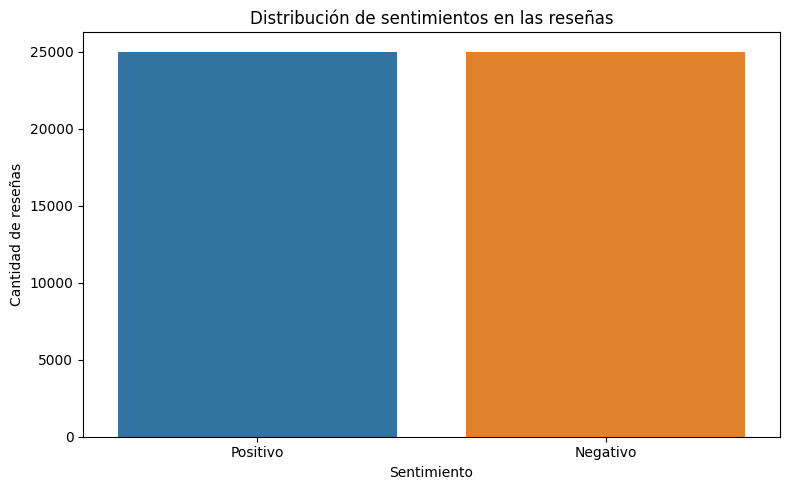

In [5]:
# Crear carpeta para guardar los resultados
os.makedirs("resultados", exist_ok=True)

# Crear gráfica
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentimiento_texto",
    hue="sentimiento_texto",
    legend=False
)

plt.title("Distribución de sentimientos en las reseñas")
plt.xlabel("Sentimiento")
plt.ylabel("Cantidad de reseñas")

plt.tight_layout()

# Guardar gráfica
plt.savefig(
    "resultados/distribucion_sentimientos.png",
    dpi=150
)

plt.show()

Longitud mínima: 11
Longitud máxima: 2494
Longitud promedio: 238.71
Longitud mediana: 178.0


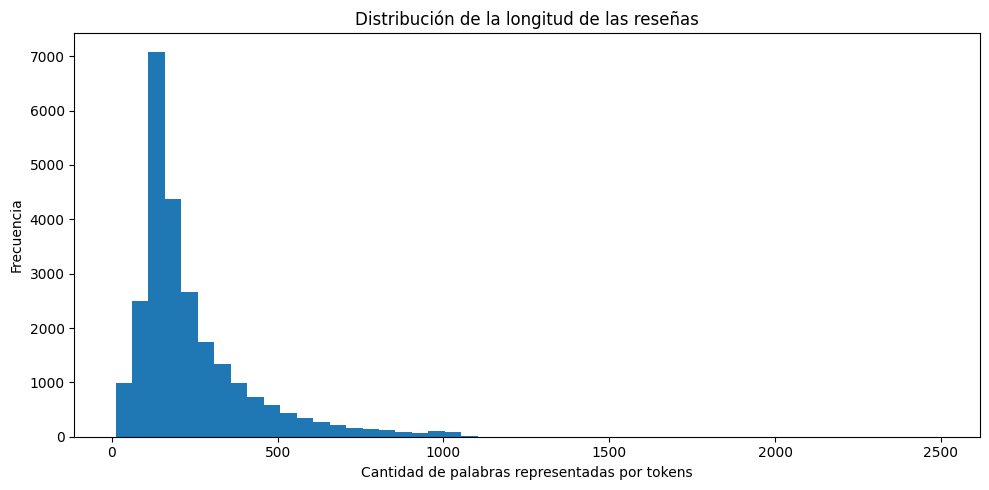

In [6]:
# Analizar la longitud de las reseñas
longitudes = [len(resena) for resena in X_train_original]

print("Longitud mínima:", min(longitudes))
print("Longitud máxima:", max(longitudes))
print("Longitud promedio:", round(np.mean(longitudes), 2))
print("Longitud mediana:", np.median(longitudes))

# Graficar la distribución de las longitudes
plt.figure(figsize=(10, 5))

plt.hist(longitudes, bins=50)

plt.title("Distribución de la longitud de las reseñas")
plt.xlabel("Cantidad de palabras representadas por tokens")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.savefig("resultados/longitud_resenas.png", dpi=150)
plt.show()

In [7]:
# Dividir el conjunto original de entrenamiento
X_train, X_val, y_train, y_val = train_test_split(
    X_train_original,
    y_train_original,
    test_size=0.20,
    random_state=42,
    stratify=y_train_original
)

# Convertir las etiquetas a formato numérico
y_train = np.asarray(y_train, dtype=np.float32)
y_val = np.asarray(y_val, dtype=np.float32)
y_test = np.asarray(y_test_original, dtype=np.float32)

# Mostrar la distribución
print("DATOS DIVIDIDOS")
print("----------------")
print("Entrenamiento:", len(X_train))
print("Validación:", len(X_val))
print("Prueba:", len(X_test_original))
print("Total:", len(X_train) + len(X_val) + len(X_test_original))

DATOS DIVIDIDOS
----------------
Entrenamiento: 20000
Validación: 5000
Prueba: 25000
Total: 50000


In [8]:
# Ajustar todas las reseñas a 200 tokens
X_train_pad = pad_sequences(
    X_train,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_original,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

# Mostrar las dimensiones finales
print("DIMENSIONES DE LOS DATOS")
print("------------------------")
print("Entrenamiento:", X_train_pad.shape)
print("Validación:", X_val_pad.shape)
print("Prueba:", X_test_pad.shape)

DIMENSIONES DE LOS DATOS
------------------------
Entrenamiento: (20000, 200)
Validación: (5000, 200)
Prueba: (25000, 200)


In [9]:
# Construir la red neuronal LSTM
model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64,
        mask_zero=True
    ),

    Bidirectional(
        LSTM(32)
    ),

    Dropout(0.5),

    Dense(
        16,
        activation="relu"
    ),

    Dense(
        1,
        activation="sigmoid"
    )
])

# Configurar el entrenamiento
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Mostrar la arquitectura
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Configurar parada temprana
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Entrenar el modelo
history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=8,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 261ms/step - accuracy: 0.9166 - loss: 0.2192 - val_accuracy: 0.8578 - val_loss: 0.3520
Epoch 2/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 80s 256ms/step - accuracy: 0.9507 - loss: 0.1390 - val_accuracy: 0.8386 - val_loss: 0.4625
Epoch 3/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 255ms/step - accuracy: 0.9599 - loss: 0.1104 - val_accuracy: 0.8426 - val_loss: 0.5236


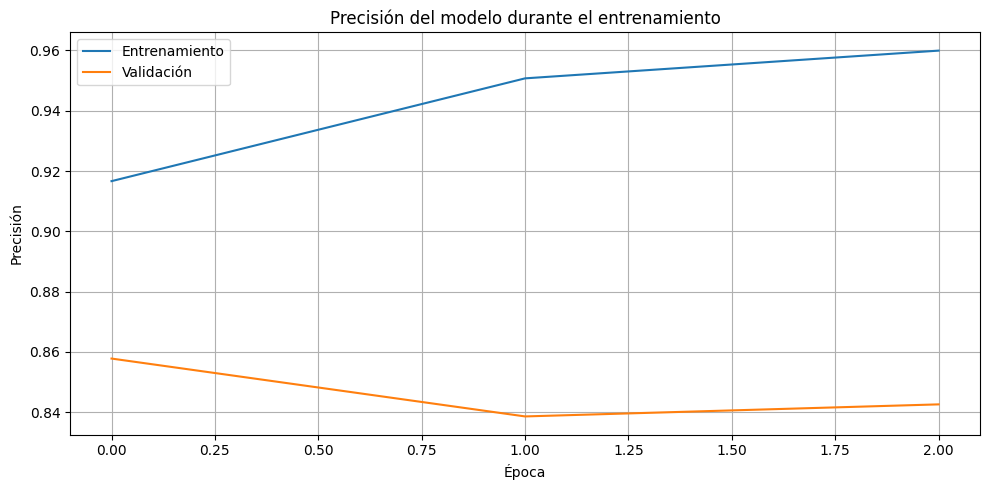

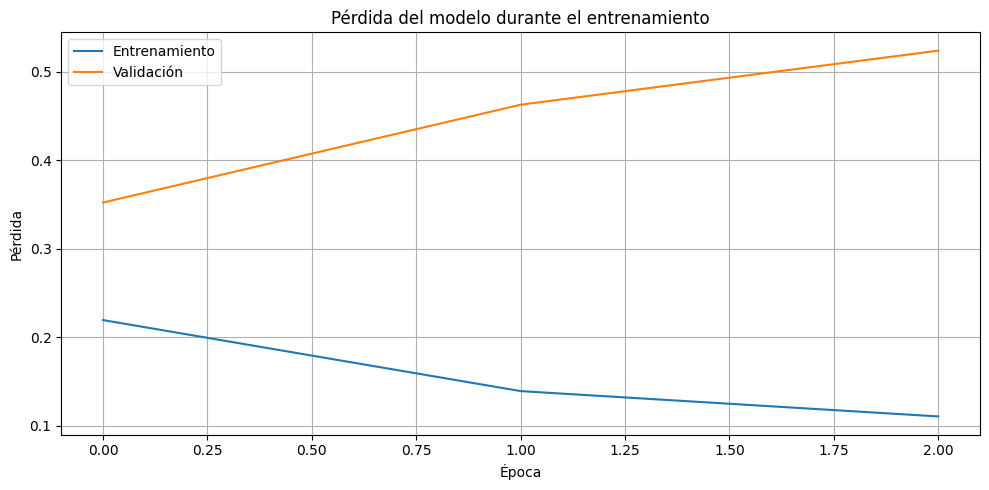

In [12]:
# Gráfica de precisión
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Entrenamiento")
plt.plot(history.history["val_accuracy"], label="Validación")

plt.title("Precisión del modelo durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Precisión")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("resultados/precision_entrenamiento.png", dpi=150)
plt.show()


# Gráfica de pérdida
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")

plt.title("Pérdida del modelo durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("resultados/perdida_entrenamiento.png", dpi=150)
plt.show()

In [13]:
# Obtener las probabilidades de predicción
probabilidades = model.predict(X_test_pad, verbose=1)

# Convertir probabilidades en clases
y_pred = (probabilidades >= 0.5).astype(int).flatten()

# Calcular métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("EVALUACIÓN FINAL DEL MODELO")
print("===========================")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precisión: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nREPORTE DE CLASIFICACIÓN")
print("========================")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negativo", "Positivo"]
))

782/782 ━━━━━━━━━━━━━━━━━━━━ 37s 46ms/step
EVALUACIÓN FINAL DEL MODELO
Accuracy:  0.8389
Precisión: 0.8773
Recall:    0.7880
F1-score:  0.8302

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

    Negativo       0.81      0.89      0.85     12500
    Positivo       0.88      0.79      0.83     12500

    accuracy                           0.84     25000
   macro avg       0.84      0.84      0.84     25000
weighted avg       0.84      0.84      0.84     25000



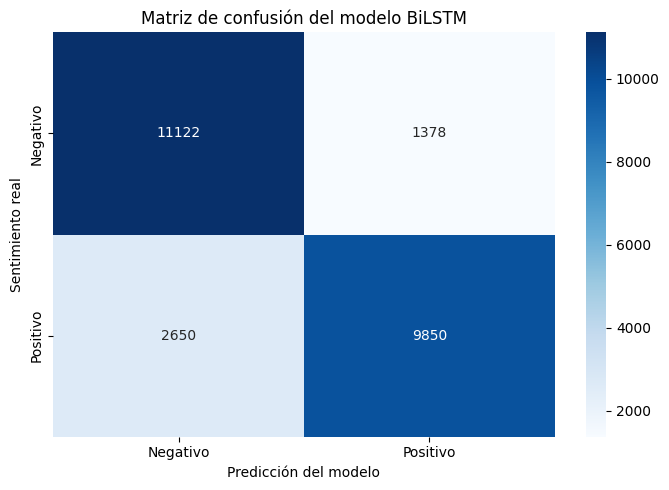

Matriz de confusión:
[[11122  1378]
 [ 2650  9850]]


In [14]:
# Calcular matriz de confusión
matriz = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negativo", "Positivo"],
    yticklabels=["Negativo", "Positivo"]
)

plt.title("Matriz de confusión del modelo BiLSTM")
plt.xlabel("Predicción del modelo")
plt.ylabel("Sentimiento real")
plt.tight_layout()

plt.savefig("resultados/matriz_confusion.png", dpi=150)
plt.show()

print("Matriz de confusión:")
print(matriz)

In [15]:
# Crear tabla con 10 predicciones
resultados_predicciones = pd.DataFrame({
    "Sentimiento real": [
        "Positivo" if valor == 1 else "Negativo"
        for valor in y_test[:10]
    ],
    "Sentimiento predicho": [
        "Positivo" if valor == 1 else "Negativo"
        for valor in y_pred[:10]
    ],
    "Probabilidad positiva": [
        round(float(valor), 4)
        for valor in probabilidades[:10].flatten()
    ]
})

print("PRIMERAS 10 PREDICCIONES")
display(resultados_predicciones)

# Guardar resultados en CSV
resultados_predicciones.to_csv(
    "resultados/10_predicciones.csv",
    index=False
)

PRIMERAS 10 PREDICCIONES


,Sentimiento real,Sentimiento predicho,Probabilidad positiva
0,Negativo,Negativo,0.0150
1,Positivo,Positivo,0.9893
2,Positivo,Negativo,0.4622
3,Negativo,Negativo,0.0916
4,Positivo,Positivo,0.9767
5,Positivo,Positivo,0.9057
6,Positivo,Positivo,0.5231
7,Negativo,Negativo,0.0110
8,Negativo,Positivo,0.9767
9,Positivo,Negativo,0.1658


In [16]:
# Crear carpeta para guardar el modelo
os.makedirs("modelo", exist_ok=True)

# Guardar modelo entrenado
model.save("modelo/modelo_lstm.keras")

# Obtener el vocabulario original de IMDB
word_index = imdb.get_word_index()

# Guardar vocabulario y parámetros de procesamiento
with open("modelo/tokenizer.pkl", "wb") as archivo:
    pickle.dump({
        "word_index": word_index,
        "vocab_size": VOCAB_SIZE,
        "max_length": MAX_LENGTH
    }, archivo)

print("MODELO Y VOCABULARIO GUARDADOS CORRECTAMENTE")
print("Modelo: modelo/modelo_lstm.keras")
print("Vocabulario: modelo/tokenizer.pkl")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
MODELO Y VOCABULARIO GUARDADOS CORRECTAMENTE
Modelo: modelo/modelo_lstm.keras
Vocabulario: modelo/tokenizer.pkl


In [17]:
import shutil

shutil.make_archive(
    "modelo_entrenado",
    "zip",
    ".",
    "modelo"
)

print("Archivos del modelo comprimidos correctamente.")

Archivos del modelo comprimidos correctamente.


In [18]:
from google.colab import files

files.download("modelo_entrenado.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>